# Stepwise, all-subsets and composite-index regression

This notebook extends the regression of notebook 7. It answers three questions:

1. **Hierarchical (stepwise) regression:** how much does each group of characteristics add to the explained variation (ΔR²), and how do the coefficients of the other variables change when a new group is added? A coefficient that shrinks or changes sign when another variable enters shows that the two variables are interdependent.
2. **All-subsets regression:** which combination of variables explains the most variation, and how much is gained by adding more variables?
3. **Composite indices:** strongly correlated pairs (|r| ≥ 0.75 in notebook 6) are combined into one index instead of dropping one of them.

The variables are entered in an order chosen in advance on theoretical grounds, not selected automatically on p-values; automatic selection on p-values tends to find chance results.

**Input:** `data/processed/all_variables_per_municipality.csv` (notebook 6).

**Outputs:** `data/processed/stepwise_results.csv`, `data/processed/all_subsets_results.csv`, `data/processed/composite_model_results.csv`, `figures/figure_stepwise_coefficients.png`, `figures/figure_all_subsets.png`

In [11]:
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor

PROCESSED = "../data/processed/"
FIGURES = "../figures/"

## 1. Load and prepare the data

As in notebook 7, the columns get short English names, population density is replaced by its logarithm, municipalities with a missing value are left out and all variables are converted to z-scores. All models in this notebook therefore use the **same** municipalities, so their R² values can be compared.

In [12]:
df = pd.read_csv(PROCESSED + "all_variables_per_municipality.csv")

df = df.rename(columns={
    "gemeente": "municipality",
    "laadpunten_per_1000_huishoudens": "charging",
    "med_gestandaardiseerd_inkomen_keur": "income",
    "hoogopgeleid_pct": "education",
    "ouderen_65plus_pct": "age65",
    "linkse_stemmen_pct": "left_vote",
    "meergezinswoning_pct": "apartments",
})
df["log_density"] = np.log(df["bevolkingsdichtheid"])

# Readable names for tables and figures
LABELS = {
    "income": "Median income",
    "education": "Highly educated (%)",
    "age65": "Residents 65+ (%)",
    "left_vote": "Left-wing vote share (%)",
    "log_density": "Population density (log)",
    "apartments": "Apartments (%)",
}

columns = ["charging"] + list(LABELS)
data = df[["municipality"] + columns].dropna()
print("Municipalities used:", len(data), "of", len(df))
print("Left out (missing income):", sorted(set(df["municipality"]) - set(data["municipality"])))

z = data.copy()
for col in columns:
    z[col] = (data[col] - data[col].mean()) / data[col].std()

Municipalities used: 339 of 342
Left out (missing income): ['Rozendaal', 'Schiermonnikoog', 'Vlieland']


## 2. Helper functions

We fit many models in this notebook, so the steps that repeat are put in functions:
- `fit_model` estimates a model with the given variables. It returns two versions: the ordinary OLS fit (used for R² and the F-test on ΔR²) and the fit with robust HC3 standard errors (used for the p-values of the coefficients, as in notebook 7).
- `max_vif` returns the highest VIF in a model, as a check on multicollinearity.
- `stars` turns a p-value into significance stars.

In [13]:
def fit_model(variables):
    """Fit charging ~ variables on the z-scores. Return the ordinary and the robust (HC3) fit."""
    formula = "charging ~ " + " + ".join(variables)
    ordinary = smf.ols(formula, data=z).fit()
    robust = smf.ols(formula, data=z).fit(cov_type="HC3")
    return ordinary, robust


def max_vif(variables):
    """Highest variance inflation factor of the variables in one model."""
    if len(variables) < 2:
        return 1.0
    X = sm.add_constant(z[list(variables)])
    vifs = []
    for i in range(1, X.shape[1]):          # position 0 is the constant
        vifs.append(variance_inflation_factor(X.values, i))
    return max(vifs)


def stars(p):
    """Significance stars: * p < 0.05, ** p < 0.01, *** p < 0.001."""
    if p < 0.001:
        return "***"
    elif p < 0.01:
        return "**"
    elif p < 0.05:
        return "*"
    else:
        return ""

## 3. Hierarchical regression

The groups of characteristics are added one at a time, in the order of the research questions:

| Step | Added | Group (sub-question) |
|---|---|---|
| 1 | Median income | Socioeconomic (SQ2) |
| 2 | Highly educated | Socioeconomic (SQ2) |
| 3 | Residents 65+ | Demographic (SQ3) |
| 4 | Left-wing vote share | Political (SQ4) |
| 5 | Population density (log) | Need (SQ5) |
| 6 | Apartments | Need (SQ5) |

For each step we report R², adjusted R², the increase in R² (ΔR²) with an F-test (is the increase significant?), the highest VIF and the β of every variable in the model.

In [14]:
ORDER = ["income", "education", "age65", "left_vote", "log_density", "apartments"]


def hierarchical(order):
    """Add the variables one at a time and collect the results of every step."""
    rows = []
    previous = None
    for step in range(1, len(order) + 1):
        variables = order[:step]
        ordinary, robust = fit_model(variables)

        if previous is None:
            delta_r2 = ordinary.rsquared
            p_delta = ordinary.f_pvalue                       # step 1: test against no model
        else:
            delta_r2 = ordinary.rsquared - previous.rsquared
            p_delta = ordinary.compare_f_test(previous)[1]    # F-test: is the increase significant?

        row = {"Step": step, "Added": LABELS[order[step - 1]],
               "R²": ordinary.rsquared, "Adj. R²": ordinary.rsquared_adj,
               "ΔR²": delta_r2, "p (ΔR²)": p_delta, "Max VIF": max_vif(variables)}
        for var in variables:
            row[LABELS[var]] = f"{robust.params[var]:+.2f}{stars(robust.pvalues[var])}"
        rows.append(row)
        previous = ordinary
    return pd.DataFrame(rows).set_index("Step")


stepwise = hierarchical(ORDER)
stepwise.to_csv(PROCESSED + "stepwise_results.csv")
stepwise.round(3)

,Added,R²,Adj. R²,ΔR²,p (ΔR²),Max VIF,Median income,Highly educated (%),Residents 65+ (%),Left-wing vote share (%),Population density (log),Apartments (%)
Step,,,,,,,,,,,,
1,Median income,0.113,0.111,0.113,0.000,1.000,+0.34***,NaN,NaN,NaN,NaN,NaN
2,Highly educated (%),0.136,0.131,0.022,0.003,1.404,+0.24***,+0.18**,NaN,NaN,NaN,NaN
3,Residents 65+ (%),0.241,0.234,0.105,0.000,1.416,+0.26***,+0.14*,-0.33***,NaN,NaN,NaN
4,Left-wing vote share (%),0.255,0.247,0.015,0.010,6.789,+0.39***,-0.14,-0.31***,+0.27**,NaN,NaN
5,Population density (log),0.364,0.354,0.108,0.000,6.804,+0.42***,-0.18,-0.13*,+0.10,+0.44***,NaN
6,Apartments (%),0.385,0.374,0.021,0.001,7.355,+0.54***,-0.29*,-0.08,+0.06,+0.30***,+0.29***


*β = standardised coefficient, robust (HC3) significance: \* p < 0.05, \*\* p < 0.01, \*\*\* p < 0.001. An empty cell (NaN) means the variable is not yet in the model.*

The figure below shows how the β of each variable changes as the other variables are added. A line that moves towards zero means that part of the earlier effect actually ran through a variable that was added later.

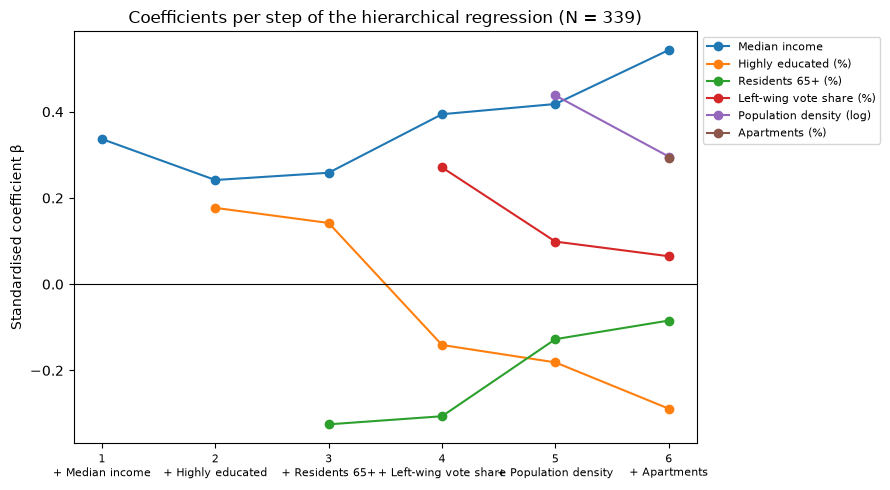

In [15]:
steps = range(1, len(ORDER) + 1)

fig, ax = plt.subplots(figsize=(9, 5))
for k, var in enumerate(ORDER):
    betas = []
    for step in steps:
        if step <= k:
            betas.append(np.nan)               # variable not yet in the model
        else:
            ordinary, robust = fit_model(ORDER[:step])
            betas.append(robust.params[var])
    ax.plot(steps, betas, marker="o", label=LABELS[var])

ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticks(list(steps))
ax.set_xticklabels([f"{i}\n+ {LABELS[v].split(' (')[0]}" for i, v in zip(steps, ORDER)], fontsize=8)
ax.set_ylabel("Standardised coefficient β")
ax.set_title(f"Coefficients per step of the hierarchical regression (N = {len(data)})")
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.savefig(FIGURES + "figure_stepwise_coefficients.png", dpi=200, bbox_inches="tight")
plt.show()

### 3b. Order check: need first

ΔR² depends on the order in which variables are added. To see how much the socioeconomic characteristics add **on top of** need, the order is reversed: need first, income last.

In [16]:
ORDER_NEED_FIRST = ["log_density", "apartments", "age65", "left_vote", "education", "income"]

stepwise_need_first = hierarchical(ORDER_NEED_FIRST)
stepwise_need_first[["Added", "R²", "Adj. R²", "ΔR²", "p (ΔR²)"]].round(3)

,Added,R²,Adj. R²,ΔR²,p (ΔR²)
Step,,,,,
1,Population density (log),0.236,0.234,0.236,0.000
2,Apartments (%),0.237,0.232,0.000,0.646
3,Residents 65+ (%),0.252,0.246,0.016,0.008
4,Left-wing vote share (%),0.252,0.243,0.000,0.903
5,Highly educated (%),0.298,0.287,0.046,0.000
6,Median income,0.385,0.374,0.087,0.000


## 4. All-subsets regression

All 63 possible combinations of the six variables are estimated. `itertools.combinations(ORDER, k)` gives every combination of `k` variables. For each number of variables the best model (highest adjusted R²) is shown. Adjusted R² and AIC both penalise extra variables, so they show whether an extra variable is worth adding. The highest VIF in each model is shown as a check on multicollinearity (VIF > 5 is a warning sign).

In [17]:
rows = []
for k in range(1, len(ORDER) + 1):
    for combo in itertools.combinations(ORDER, k):
        ordinary, robust = fit_model(combo)

        all_significant = True
        for var in combo:
            if robust.pvalues[var] >= 0.05:
                all_significant = False

        rows.append({"k": k,
                     "Variables": " + ".join(LABELS[v] for v in combo),
                     "Adj. R²": ordinary.rsquared_adj,
                     "AIC": ordinary.aic,
                     "Max VIF": max_vif(combo),
                     "All significant": all_significant})

subsets = pd.DataFrame(rows).sort_values("Adj. R²", ascending=False)
subsets.to_csv(PROCESSED + "all_subsets_results.csv", index=False)

# Best model for each number of variables
best_per_k = subsets.sort_values("Adj. R²", ascending=False).groupby("k").head(1).sort_values("k").set_index("k")
best_per_k.round(3)

,Variables,Adj. R²,AIC,Max VIF,All significant
k,,,,,
1,Population density (log),0.234,873.771,1.000,True
2,Median income + Population density (log),0.339,824.822,1.000,True
3,Median income + Residents 65+ (%) + Population...,0.352,818.840,1.291,True
4,Median income + Highly educated (%) + Populati...,0.371,809.627,3.787,True
5,Median income + Highly educated (%) + Resident...,0.375,808.886,4.043,False
6,Median income + Highly educated (%) + Resident...,0.374,810.444,7.355,False


In [18]:
# Top 10 of all 63 models
subsets.head(10).round(3)

,k,Variables,Adj. R²,AIC,Max VIF,All significant
58,5,Median income + Highly educated (%) + Resident...,0.375,808.886,4.043,False
62,6,Median income + Highly educated (%) + Resident...,0.374,810.444,7.355,False
46,4,Median income + Highly educated (%) + Populati...,0.371,809.627,3.787,True
59,5,Median income + Highly educated (%) + Left-win...,0.370,811.200,7.152,False
60,5,Median income + Residents 65+ (%) + Left-wing ...,0.364,814.630,3.779,False
50,4,Median income + Left-wing vote share (%) + Pop...,0.358,816.963,3.602,True
49,4,Median income + Residents 65+ (%) + Population...,0.357,817.048,2.684,True
42,4,Median income + Highly educated (%) + Resident...,0.354,818.773,1.840,False
56,5,Median income + Highly educated (%) + Resident...,0.354,819.772,6.804,False
26,3,Median income + Residents 65+ (%) + Population...,0.352,818.840,1.291,True


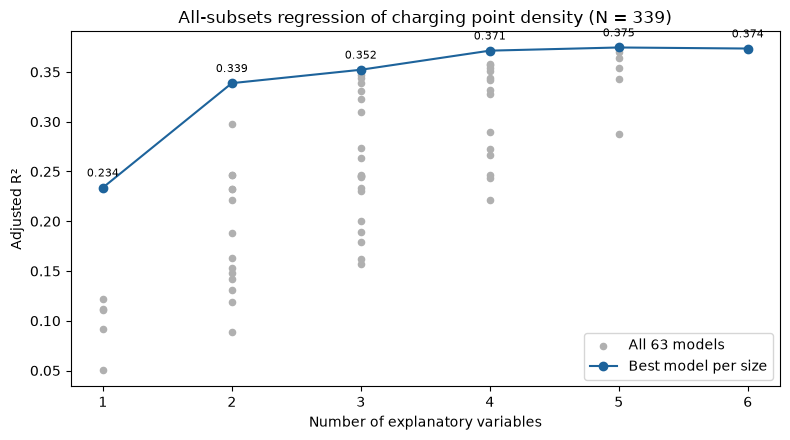

In [19]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(subsets["k"], subsets["Adj. R²"], color="#b0b0b0", s=20, label="All 63 models")
ax.plot(best_per_k.index, best_per_k["Adj. R²"], color="#1d639b", marker="o", label="Best model per size")
for k in best_per_k.index:
    value = best_per_k.loc[k, "Adj. R²"]
    ax.annotate(f"{value:.3f}", (k, value), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8)
ax.set_xlabel("Number of explanatory variables")
ax.set_ylabel("Adjusted R²")
ax.set_title(f"All-subsets regression of charging point density (N = {len(data)})")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(FIGURES + "figure_all_subsets.png", dpi=200, bbox_inches="tight")
plt.show()

## 5. Composite indices

Two pairs of variables are so strongly correlated that they largely measure the same thing. Instead of dropping one variable of each pair, the two are combined into one index: the average of their z-scores, standardised again so its β can be compared with the other variables.

- **Urbanity (need)** = population density (log) + share of apartments
- **Progressive profile** = share of highly educated residents + left-wing vote share

In [20]:
print("r (log density, apartments):", round(data["log_density"].corr(data["apartments"]), 2))
print("r (education, left-wing vote share):", round(data["education"].corr(data["left_vote"]), 2))

z["urbanity"] = (z["log_density"] + z["apartments"]) / 2
z["progressive"] = (z["education"] + z["left_vote"]) / 2
z["urbanity"] = (z["urbanity"] - z["urbanity"].mean()) / z["urbanity"].std()
z["progressive"] = (z["progressive"] - z["progressive"].mean()) / z["progressive"].std()

LABELS["urbanity"] = "Urbanity index"
LABELS["progressive"] = "Progressive index"
COMPOSITE = ["income", "age65", "urbanity", "progressive"]

ordinary, robust = fit_model(COMPOSITE)
X = sm.add_constant(z[COMPOSITE])

rows = []
for i, var in enumerate(COMPOSITE, start=1):
    rows.append({"Variable": LABELS[var], "β": robust.params[var], "p-value": robust.pvalues[var],
                 "VIF": variance_inflation_factor(X.values, i)})
rows.append({"Variable": "Adj. R²", "β": ordinary.rsquared_adj})
rows.append({"Variable": "N", "β": ordinary.nobs})

composite = pd.DataFrame(rows).set_index("Variable")
composite.index.name = None
composite.to_csv(PROCESSED + "composite_model_results.csv")
composite.round(3)

r (log density, apartments): 0.75
r (education, left-wing vote share): 0.78


,β,p-value,VIF
Median income,0.452,0.000,1.323
Residents 65+ (%),-0.092,0.088,1.403
Urbanity index,0.556,0.000,2.353
Progressive index,-0.186,0.005,2.018
Adj. R²,0.371,NaN,NaN
N,339.000,NaN,NaN
